# Full Pipeline on an A0 Star

This notebook serves as a full tutorial of the use of the repository (up to the 18 of Nov).

We will study the A0 star SDSS J172637.24+264127.6.

Units throughout: wavelengths in Angstrom (vacuum), velocities in km/s, column densities as $\log10(N / cm^{-2})$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. The shared data structures

The package has three dataclasses (`spectral_diag/data_classes.py`). Every module reads and writes them.

| Class | What it holds | Mutable? |
|---|---|---|
| `Spectrum` | `wave`, `flux`, `error`, plus `continuum` and `meta` filled in by later steps | yes |
| `Line` | one atomic transition: `species`, `wave_rest`, `f`, `gamma`, `name` | no (frozen) |
| `Absorber` | one absorbing system of one species: `z`, `logN`, `b`, `lines` | yes |

### 1.1 `Spectrum`

We build one by hand with 5 pixels and a dip in the middle.

In [2]:
from spectral_diag import Spectrum

spectrum_small = Spectrum(
    wave=np.array([5000.0, 5001.0, 5002.0, 5003.0, 5004.0]),
    flux=np.array([1.0, 0.9, 0.5, 0.9, 1.0]),
    error=np.full(5, 0.05),
)

`Spectrum` contains these different parts:

| Part | Type | Meaning | Filled by |
|---|---|---|---|
| `wave` | array | observed wavelength grid, in Angstrom (vacuum) | the reader |
| `flux` | array | flux at each wavelength. It must have the same length as `wave` | the reader |
| `error` | array | 1-sigma flux uncertainty per pixel, written in the same units as `flux` | the reader |
| `continuum` | array or `None` | the level of the continuum at each wavelength | `fit_continuum` (`None` until then) |
| `meta` | dict | the metadata (keys from the observation, see below) | the reader or the synthetic generator |
| `check_valid()` | method | this method raises `ValueError` if `wave` is not strictly increasing or if the `error` is not > 0 at every pixel | |
| `cut(window)` | method | this method slices the `Spectrum`, creating a new one (`continuum` is also cut, `meta` is shared) | |

Constructing a `Spectrum` does not automatically validate it, which is why `check_valid()` exists. It is called before fitting or searching.

Some keys of `meta` used so far:

| Keys | Meaning |
|---|---|
| `instrument`, `source`, `obs_id` | provenance |
| `ra`, `dec` (deg), `mjd`, `exptime` (s) | observation |
| `wave_frame`, `flux_unit` | conventions |
| `fwhm_kms`, `R` | instrumental FWHM (km/s; for SDSS, the median over the spectrum) and resolving power, $R = c / \mathrm{FWHM}$ |
| `pixel_dex` | pixel width in log10(Angstrom) |
| `snr` | median signal-to-noise per pixel |
| `absorbers` | injected truth (synthetic spectra only) |

In [3]:
# Use case of check_valid().
spectrum_small.check_valid()
# Nothing is printed: check_valid() returns None and raises only when invalid

broken_cases = {
    "zero error": Spectrum(
        wave=spectrum_small.wave,
        flux=spectrum_small.flux,
        error=np.zeros(5), # Errors must be positive
    ),
    "decreasing wave": Spectrum(
        wave=spectrum_small.wave[::-1], # Wave must be increasing
        flux=spectrum_small.flux,
        error=spectrum_small.error,
    ),
}

for case_name, broken_spectrum in broken_cases.items():
    try:
        broken_spectrum.check_valid()
    except ValueError as error:
        print(f"{case_name}: {error}")

zero error: error must be positive at every pixel
decreasing wave: wave must be strictly increasing


### 1.2 `Line`

One atomic transition, from the line list. As an example we will build the CaII K line by hand: vacuum rest wavelength in Angstrom, oscillator strength `f` and damping constant `gamma` in s $^{-1}$ (Morton 2003).

`Line` is a frozen dataclass: lines are reference data and are shared by many objects, so nobody should change one in place.

In [4]:
from spectral_diag import Line

calcium_k = Line(species="CaII", wave_rest=3934.777, f=0.627, gamma=1.47e8)
print(calcium_k)

print(calcium_k.name)

Line(species='CaII', wave_rest=3934.777, f=0.627, gamma=147000000.0, name='CaII 3934.777')
CaII 3934.777


In [5]:
# Assigning to a frozen dataclass raises FrozenInstanceError, a kind of AttributeError
try:
    calcium_k.f = 0.5
except AttributeError as error:
    print("AttributeError:", error)

# To change a Line, build a new one with the new value
calcium_k_weak = Line(
    species=calcium_k.species,
    wave_rest=calcium_k.wave_rest,
    f=0.5,
    gamma=calcium_k.gamma,
)
print(calcium_k.f, calcium_k_weak.f)

AttributeError: cannot assign to field 'f'
0.627 0.5


In [6]:
print(calcium_k.name)
print(calcium_k_weak.name)

CaII 3934.777
CaII 3934.777


### 1.3 `Absorber`

An `Absorber` groups what we want to find out for one species: redshift `z`, column density `logN`, Doppler parameter `b` (km/s) and the `Line` objects used. Here the values are only illustrative.

In [7]:
from spectral_diag import Absorber

calcium_cloud = Absorber(species="CaII", z=0.0, logN=12.0, b=5.0, lines=[calcium_k])
print(calcium_cloud)

# Unlike Line, an Absorber is meant to be updated, e.g. by a fit
calcium_cloud.logN = 12.5
print(calcium_cloud.logN)

Absorber(species='CaII', z=0.0, logN=12.0, b=5.0, lines=[Line(species='CaII', wave_rest=3934.777, f=0.627, gamma=147000000.0, name='CaII 3934.777')])
12.5


## 2. Downloading and reading the star

`query_mast` (`spectral_diag/mast_archive.py`) searches the MAST archive around the star (5 arcsec by default) and keeps only the observations that are spectra. MAST holds a single spectrum for this object: SDSS, plate-MJD-fiber 2182-53905-0101, with no HST data. `em_min` and `em_max` are the wavelength range covered, in nm.

In [8]:
from spectral_diag.mast_archive import query_mast

obs = query_mast("SDSS J172637.24+264127.6")
obs["obs_collection", "instrument_name", "obs_id", "em_min", "em_max"]

obs_collection,instrument_name,obs_id,em_min,em_max
str4,str17,str28,float64,float64
SDSS,SDSS Spectrograph,sdss_spectro_2182-53905-0101,380.0,920.0


`download_mast_spectra` downloads the science FITS files of these observations to `data/mast`. `productSubGroupDescription="SPECTRA"` keeps the per-object files, `spec` and `spec-lite`, and the size limit `max_size_mb` (50 MB by default) skips the catalogue-wide `specObj-dr17.fits` (~7 GB) that MAST also attaches to SDSS observations. Files already on disk are not downloaded again.

In [9]:
from pathlib import Path

from spectral_diag.mast_archive import download_mast_spectra

DOWNLOAD_DIR = Path("../data/mast")

paths = download_mast_spectra(
    obs, download_dir=DOWNLOAD_DIR, productSubGroupDescription="SPECTRA"
)
paths

INFO: Found cached file ../data/mast/spec-lite-2182-53905-0101.fits with expected size 172800. [astroquery.query]


INFO: Found cached file ../data/mast/spec-2182-53905-0101.fits with expected size 748800. [astroquery.query]


[PosixPath('../data/mast/spec-lite-2182-53905-0101.fits'),
 PosixPath('../data/mast/spec-2182-53905-0101.fits')]

`read_sdss_spec` (`spectral_diag/spectrum_reader.py`) turns an SDSS FITS file into a `Spectrum`. It reads the co-added spectrum and the pipeline results. We read the `spec-lite` file: it is the `spec` file without the individual exposures, which we do not need.

The wavelengths are vacuum heliocentric. The error is calculated as $1/\sqrt{\mathrm{ivar}}$, where ivar is the inverse variance. The pixels with no valid data(`ivar == 0`) are dropped. 

In [10]:
from spectral_diag.spectrum_reader import read_sdss_spec

SPECTRUM_PATH = DOWNLOAD_DIR / "spec-lite-2182-53905-0101.fits"

spectrum = read_sdss_spec(SPECTRUM_PATH)
print("n of pixels:", len(spectrum.wave))
print(f"wavelength range: {spectrum.wave[0]:.1f} - {spectrum.wave[-1]:.1f} A")
print(f"wavelength mean width: {np.mean(np.diff(spectrum.wave)):.4f} A and in log10: {np.mean(np.diff(np.log10(spectrum.wave))):.4e}" 
      f"dex compared to the theoretical log10 width given in the spectrum info of: {spectrum.meta["pixel_dex"]:.4e}")

# The continuum is filled in later, by fit_continuum
print("continuum:", spectrum.continuum)

n of pixels: 3772
wavelength range: 3811.5 - 9206.6 A
wavelength mean width: 1.4307 A and in log10: 1.0156e-04dex compared to the theoretical log10 width given in the spectrum info of: 1.0000e-04
continuum: None


In [11]:
for key, value in spectrum.meta.items():
    print(f"{key:12s} {value}")

instrument   SDSS
source       spec-lite-2182-53905-0101.fits
obs_id       2182-53905-0101
ra           261.6552
dec          26.690992
mjd          53905
exptime      3900.4
wave_frame   vacuum, heliocentric
pixel_dex    0.0001
flux_unit    1e-17 erg s^-1 cm^-2 Angstrom^-1
snr          61.5799674987793
z            -0.00012310095189604908
z_err        4.0423092286800966e-06
class        STAR
subclass     A0
fwhm_kms     145.46721384510857
R            2060.8936548356164


Besides the keys we saw in section 1, the reader fills in the SDSS pipeline results:

| Key | Meaning |
|---|---|
| `z`, `z_err` | redshift of the star from the SDSS pipeline |
| `class`, `subclass` | SDSS classification (here `STAR`, `A0`) |

### 2.1 The full spectrum

We plot the flux and its error with `plot_raw_spectrum` (`spectral_diag/plots.py`).

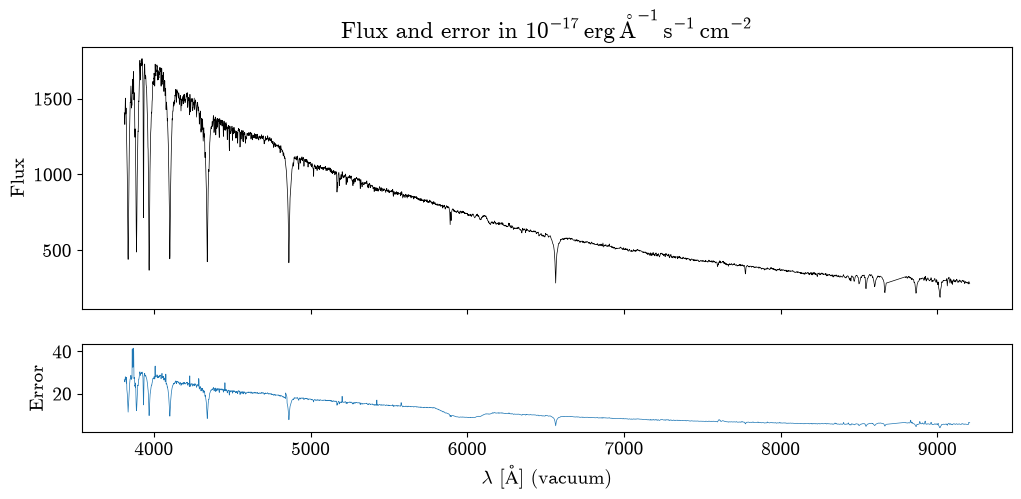

In [12]:
from spectral_diag.plots import plot_raw_spectrum

fig, axes = plot_raw_spectrum(spectrum)
plt.show()

### 2.2 The pixel grid

SDSS pixels are uniform in $\log_{10}\lambda$: the step between neighbouring pixels is always `pixel_dex` $= 10^{-4}$. In Angstrom the pixels are not equal (about 0.9 Å at 4000 Å and 2 Å at 9000 Å), but in velocity they are. For a small step,

$$\Delta(\log_{10}\lambda) = \frac{\Delta\lambda}{\lambda \ln 10}, \qquad \frac{\Delta\lambda}{\lambda} = \frac{\Delta v}{c} \quad\Rightarrow\quad \Delta v = \ln(10)\, c\, \Delta(\log_{10}\lambda) \approx 69 \text{ km/s}$$

at every wavelength.

**Why velocity matters.** The physics that shapes a line acts in velocity, not in Angstrom:

- **Line widths.** The Doppler parameter `b` and the instrumental FWHM are velocities. The same gas gives the same width in km/s to all its lines, but in Angstrom a line at 8000 Å is twice as wide as one at 4000 Å. On this grid both cover the same number of pixels.
- **Instrumental resolution.** The resolving power $R = c / \mathrm{FWHM}$ is roughly constant, so the line spread function has a fixed width in km/s (`fwhm_kms`). The line profiles can convolve with a single kernel of fixed width in pixels over the whole spectrum.
- **Redshift.** A redshift multiplies every wavelength by $(1+z)$, which is a constant shift in $\log_{10}\lambda$, i.e. the same number of pixels for every line. The fixed wavelength ratios of a species (its "comb") keep the same spacing in pixels at any $z$, which is what the identification uses.
- **Sampling.** Dividing the FWHM by the pixel width gives the number of pixels per resolution element, the same everywhere. It must be about 2 or more (Nyquist) to resolve a line.

> **Note:** the grid has one gap, at 8674–8794 Å, where the reader dropped the pixels with `ivar == 0`. Code that walks the grid pixel by pixel must not assume the next pixel is always one `pixel_dex` away.

In [13]:
from spectral_diag import constants

pixel_dex = spectrum.meta["pixel_dex"]

# A step of d(log10 lambda) is a velocity of ln(10) * c * d(log10 lambda)
pixel_kms = np.log(10) * constants.C_KMS * pixel_dex
print(f"pixel width: {pixel_kms:.1f} km/s")
print(f"pixels per resolution element: {spectrum.meta['fwhm_kms'] / pixel_kms:.1f}")

pixel width: 69.0 km/s
pixels per resolution element: 2.1


## 3. Continuum

`fit_continuum` (`spectral_diag/continuum.py`) fits the continuum with a cubic spline, with knots separated by a distance of `knot_spacing` Å, weighted by 1/error. Pixels that are below the fit at a distance of more than `clip_low` errors are rejected and the spline is refitted, until the set of used pixels stops changing. Only pixels below the fit are rejected, because absorption only removes flux.

### 3.1 Fit with the default settings

The result is a `ContinuumFit` object, formed by the `continuum` and its `error` at every pixel, the mask of `used` pixels, the number of iterations `n_iter` and the `status` (`"converged"` or `"max_iter"`).

The `used` pixels are those compatible with the continuum. The rejected ones are mostly absorption, but not only: about 2% of pure continuum pixels fall below $-2\sigma$ by chance, and the telluric $\mathrm{O}_2$ bands (6870, 7600 Å) are rejected too. Weak lines that dip less than $2\sigma$ stay used.

In [14]:
from spectral_diag.continuum import ContinuumSettings, fit_continuum

# The settings can be changed, e.g. to use a different knot spacing
print(ContinuumSettings())

fit = fit_continuum(spectrum)

print(f"{fit.used.sum()} of {fit.used.size} pixels used")

ContinuumSettings(knot_spacing=250.0, clip_low=2.0, max_iter=20)
3159 of 3772 pixels used


We plot the flux, the continuum and the rejected pixels (`~fit.used`) with `plot_continuum` (`spectral_diag/plots.py`). The rejected pixels give a first view of where the lines are, without any line list.

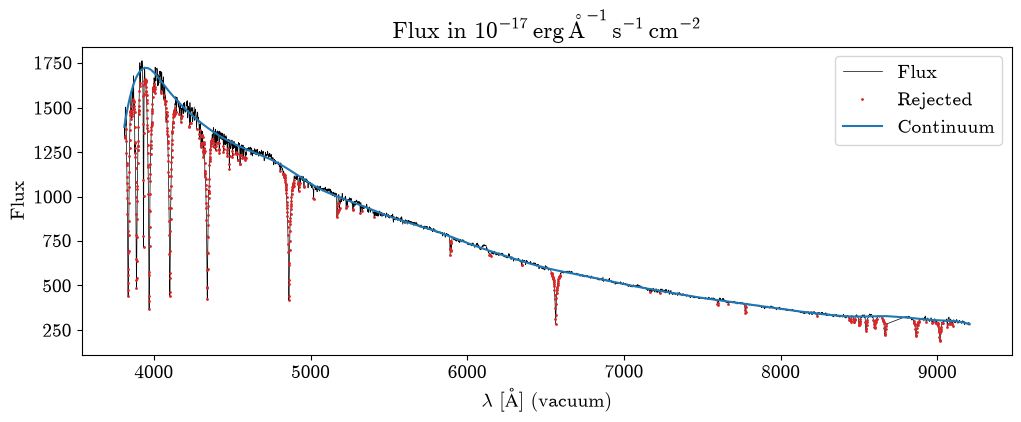

In [15]:
from spectral_diag.plots import plot_continuum

fig, ax = plot_continuum(spectrum, fit)
plt.show()

### 3.2 Choosing the knot spacing

`knot_spacing` must be wider than the broadest line, or the spline has enough freedom to follow the line instead of the continuum under it. In this cell we compare fits with different spacings.

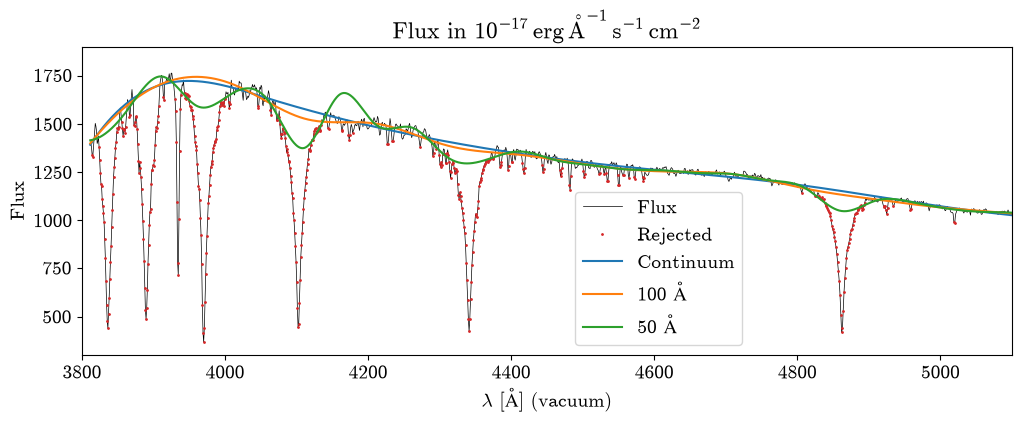

In [16]:
# Knot spacings (Angstrom) to compare with the default fit (250), and their colours.
# The colours are explicit: plot_continuum already uses blue for the default
COLOR_BY_KNOT_SPACING = {100: "tab:orange", 50: "tab:green"}
# Zoom on the blue end, where the Balmer lines are broadest (Angstrom, flux units)
BLUE_WAVE_RANGE = (3800, 5100)
BLUE_FLUX_RANGE = (300, 1900)
# Bottom centre of the legend, in axes fractions: the empty gap between Hgamma and Hbeta
LEGEND_ANCHOR = (0.62, 0.0)

# "Continuum" and the red points are those of the default fit
fig, ax = plot_continuum(spectrum, fit)
for knot_spacing, color in COLOR_BY_KNOT_SPACING.items():
    settings = ContinuumSettings(knot_spacing=knot_spacing)
    other_fit = fit_continuum(spectrum, settings)
    # cmr10 has no Å glyph in plain text, so it goes in math mode
    label = rf"{knot_spacing} $\mathrm{{\AA}}$"
    ax.plot(spectrum.wave, other_fit.continuum, color=color, label=label)

# The legend is redrawn to include the new continua
ax.legend(loc="lower center", bbox_to_anchor=LEGEND_ANCHOR)
ax.set_xlim(*BLUE_WAVE_RANGE)
ax.set_ylim(*BLUE_FLUX_RANGE)
plt.show()

With 50 Å the spline dips into $\mathrm{H}\delta$, $\mathrm{H}\gamma$ and $\mathrm{H}\beta$ (about 10% below the default at their centres) and overshoots between them, so the EWs would be underestimated. 100 Å is close to 250 Å except below 4100 Å, where the Balmer lines start to overlap. We keep the default, 250 Å.

### 3.3 Normalising

`normalise` divides the flux and the error by the continuum, so the continuum becomes 1 and a line is a dip below 1. The error of the normalised flux does not include the error of the continuum. The normalised spectrum keeps the `meta` of the original, so `meta["flux_unit"]` no longer applies to it.

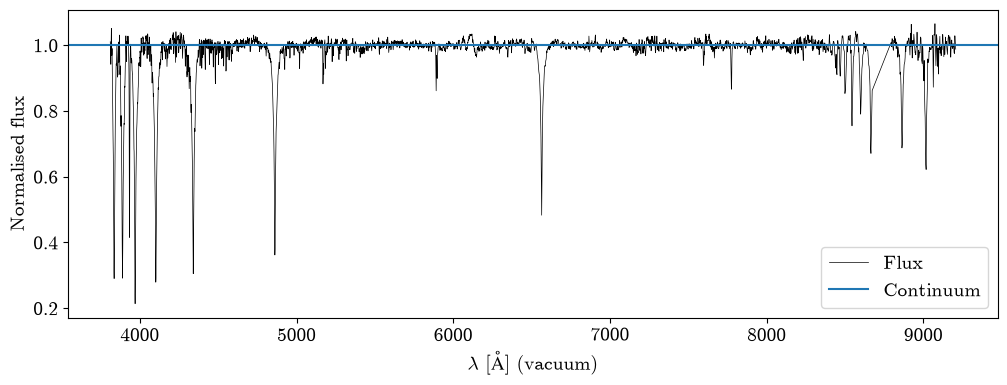

In [17]:
from spectral_diag.continuum import normalise
from spectral_diag.plots import plot_normalised

normalised_spectrum = normalise(spectrum, fit.continuum)

fig, ax = plot_normalised(normalised_spectrum)
plt.show()

The straight segment at 8674–8794 Å is the gap of the pixel grid (section 2.2), not data.

The line detection (`find_features`, next section) reads the continuum from `spectrum.continuum`, so we store the default fit there, with its error in `spectrum.continuum_error`.

In [18]:
spectrum.continuum = fit.continuum
# Propagated into the EW errors (ew_err) of the features
spectrum.continuum_error = fit.error

## 4. Detecting the features

`find_features` (`spectral_diag/detect`) finds the significant dips of the spectrum without any line list. It normalises the spectrum, $F_\mathrm{norm} = \mathrm{flux}/\mathrm{continuum}$, takes $1 - F_\mathrm{norm}$ and filters it with a matched filter (a Gaussian of the instrumental width). A feature is a run of pixels where the significance exceeds `threshold` (in $\sigma$). Each feature is then measured, and the result is an astropy `Table` with one row per feature:

| Column | Meaning |
|---|---|
| `wave`, `wave_err` | observed centre and its $1\sigma$ error, in Å (vacuum) |
| `wave_min`, `wave_max` | window of the feature, Å |
| `depth` | $1 - \min(F_\mathrm{norm})$ |
| `ew`, `ew_err` | equivalent width over the window and its $1\sigma$ error, Å |
| `snr` | detection significance, `ew / ew_err` |

### 4.1 Features at $4\sigma$

In [19]:
from spectral_diag.detect import find_features

# Detection threshold, in sigma
THRESHOLD = 4.0

features = find_features(spectrum, threshold=THRESHOLD)

print(f"{len(features)} features")
features.pprint_all()

45 features
  wave   wave_err wave_min wave_max depth   ew   ew_err  snr  
-------- -------- -------- -------- ----- ------ ------ ------
3814.806    0.307 3813.292 3815.926 0.058  0.113  0.029  3.917
3836.201    0.125 3821.202 3853.008 0.710  8.868  0.113 78.560
3858.764    0.377 3854.783 3862.780 0.097  0.540  0.052 10.296
3889.806    0.248 3871.684 3908.409 0.709 10.456  0.107 98.101
3934.250    0.032 3928.257 3940.034 0.585  2.390  0.052 46.398
3970.407    0.272 3940.941 4001.290 0.786 13.373  0.145 91.963
4005.869    0.383 4002.211 4007.745 0.065  0.207  0.037  5.639
4102.374    0.261 4068.179 4137.137 0.721 13.692  0.147 93.041
4144.373    0.489 4141.903 4145.720 0.044  0.126  0.029  4.290
4173.605    0.390 4171.575 4183.117 0.065  0.328  0.055  5.963
4227.340    0.309 4225.713 4228.633 0.052  0.118  0.025  4.677
4290.636    0.357 4288.446 4296.354 0.064  0.246  0.045  5.429
4301.841    0.250 4297.342 4305.267 0.096  0.481  0.044 10.998
4317.179    6.553 4306.257 4317.179 0.132  

### 4.2 The windows

`plot_features` (`spectral_diag/plots.py`) draws the normalised spectrum with the window of each feature shaded and its centre marked. We show the whole spectrum and two zooms: the blue end, where most features are, and a close pair near 5890 Å, to check that two nearby dips are split into two features.

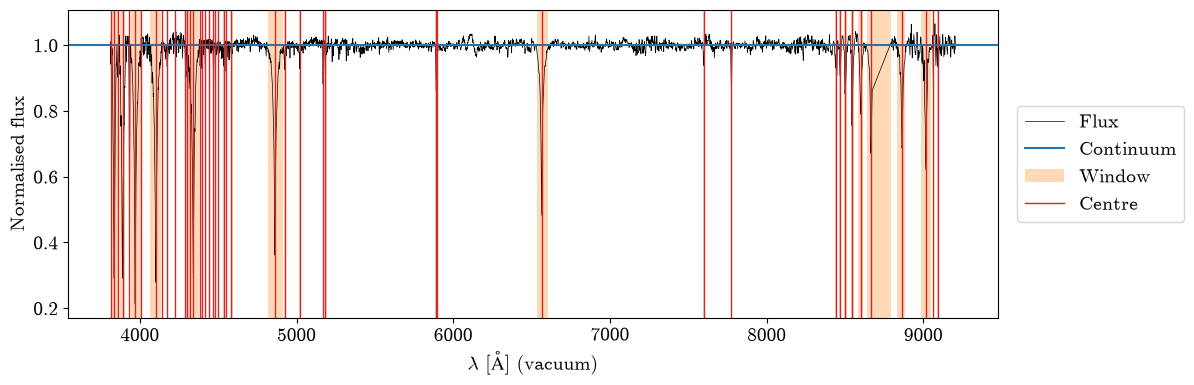

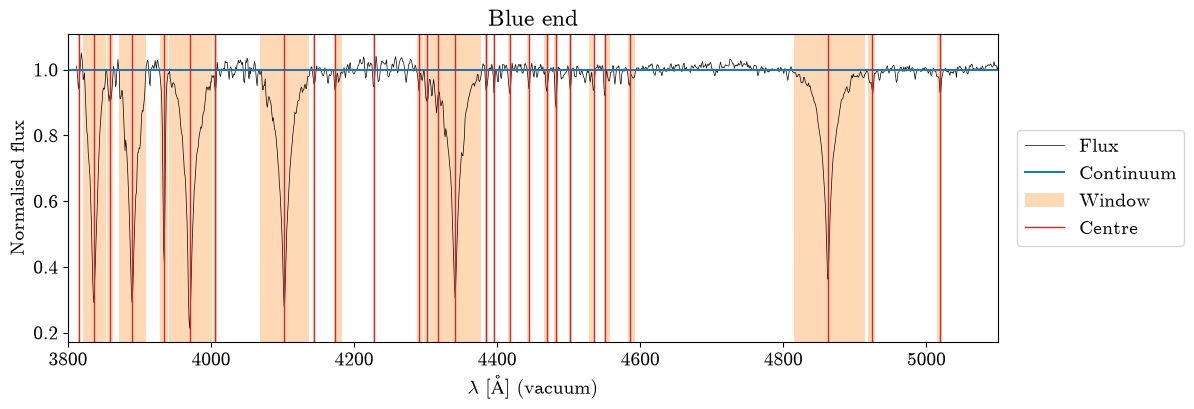

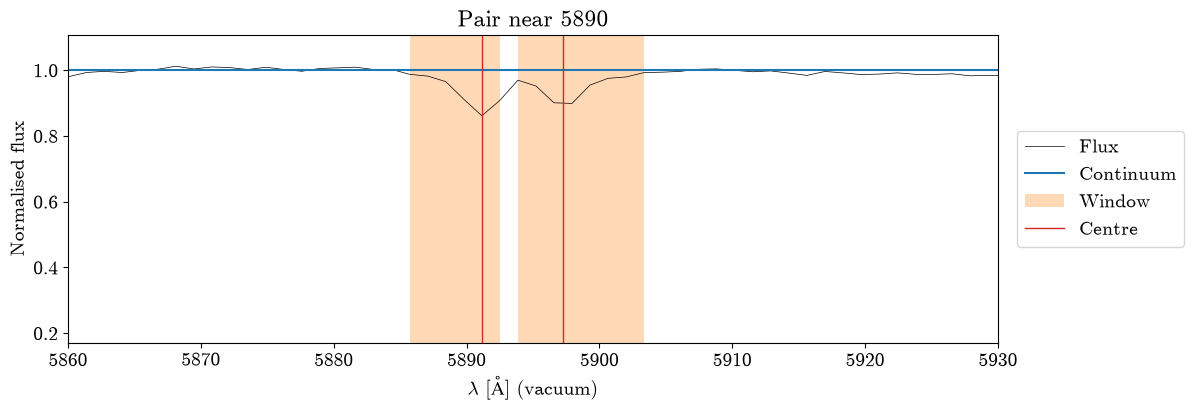

In [20]:
from spectral_diag.plots import plot_features

fig, ax = plot_features(normalised_spectrum, features)
plt.show()

fig, ax = plot_features(normalised_spectrum, features)
ax.set_title("Blue end")
ax.set_xlim(3800, 5100)
plt.show()

fig, ax = plot_features(normalised_spectrum, features)
ax.set_title("Pair near 5890")
ax.set_xlim(5860, 5930)
plt.show()

The two windows of the pair are not symmetric about their centres, because each side ends by a different rule. On the outer side the window grows until the significance falls below $1\sigma$ (`WINDOW_EDGE_SIGNIFICANCE`), which keeps the wings. On the inner side it is cut at the lowest significance between the two peaks (`split_blends`). The two centres are only about 2 FWHM apart, so the significance never gets near $1\sigma$ between them: the inner side ends one pixel after the centre, the outer side about four. As a result, part of the red wing of the left feature is counted in the EW of the right one, and the other way round. The sum of the two EWs is right, but the split between them is approximate; a joint fit of the two profiles would separate them.